# Calculate an asymmetry score of a skin lesion 

In [1]:
import sys
import os

# Add the project root to the system path to import local modules
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

In [2]:
from python.dualbranch.ham10000_dataset_manager import HAM10000DatasetManager
from python.utils.image_asymmetry import ImageAsymmetry
from python.utils.image_filters import gabor_filter, lbp_filter, glcm_filter
import matplotlib.pyplot as plt

## Load the HAM10000 dataset

In [ ]:
# load the dataset manager
dataset_manager = HAM10000DatasetManager(data_dir="../../data")

# load the dataset
# dataset = dataset_manager.load_dataset(data_dir="../../data")
dataset_manager.load_cleaned_metadata()

In [6]:
dataset_manager.df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,lesion_idx,image_hash,melanoma_binary
64,HAM_0001751,ISIC_0024698,nv,consensus,70.0,male,face,/home/vertyx/Documents/dermascan/data/raw/ISIC...,0,2085145649579717563,0
1210,HAM_0000559,ISIC_0024693,nv,follow_up,45.0,female,upper extremity,/home/vertyx/Documents/dermascan/data/raw/ISIC...,0,-7997840765378770202,0
1211,HAM_0000871,ISIC_0025964,mel,histo,40.0,female,chest,/home/vertyx/Documents/dermascan/data/raw/ISIC...,1,214845992733790304,1
1212,HAM_0000871,ISIC_0030623,mel,histo,40.0,female,chest,/home/vertyx/Documents/dermascan/data/raw/ISIC...,1,737465782077646359,1
1213,HAM_0000040,ISIC_0027190,mel,histo,80.0,male,upper extremity,/home/vertyx/Documents/dermascan/data/raw/ISIC...,1,-4921820835802982503,1


## Get random image from dataset and calculate an asymmetry score using a helper class

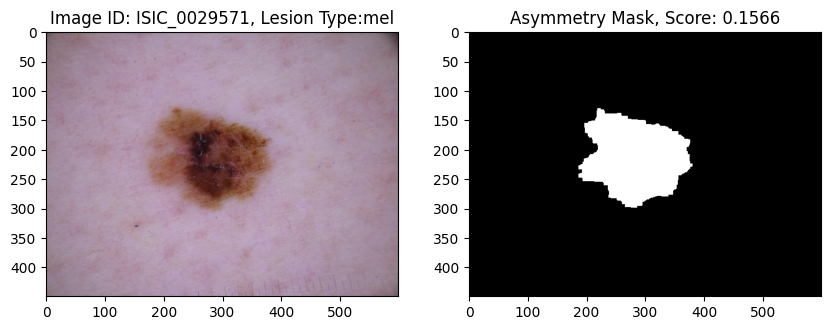

In [ ]:
image_id, lesion_type, image = dataset_manager.get_sample_image(lesion_type=None)
binary_mask = ImageAsymmetry.create_binary_mask(image=image)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image)
axes[0].set_title(f"Image ID: {image_id}, Lesion Type:{lesion_type}")
axes[1].imshow(binary_mask, cmap='gray')
axes[1].set_title(f"Asymmetry Mask, Score: {ImageAsymmetry.calculate_asymmetry(image):.4f}")
plt.show()

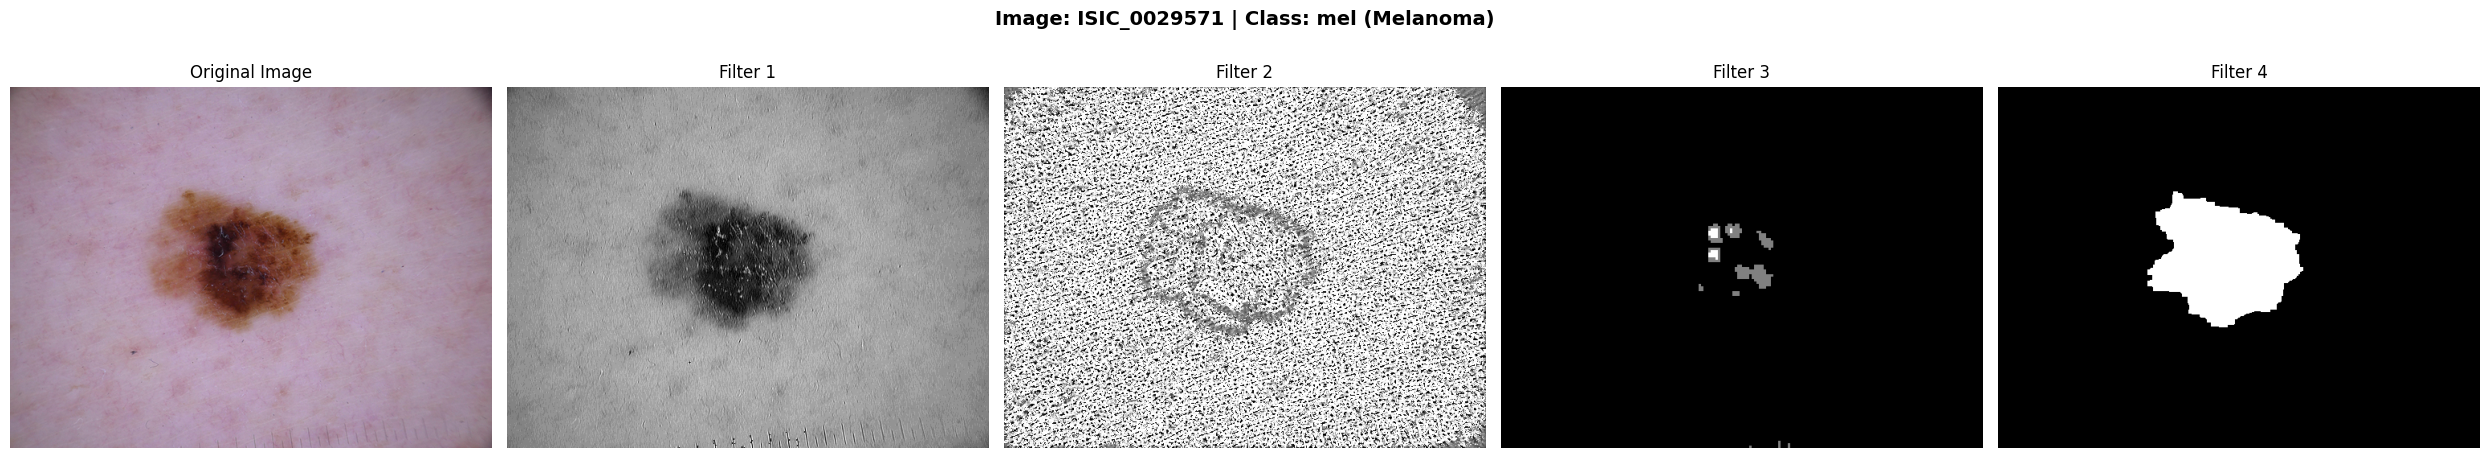

In [ ]:
dataset_manager.visualize_image_with_filters(image_id=image_id, filter_method_list=[gabor_filter, lbp_filter, glcm_filter])